In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

## 1. Dataset Description
- **Source:** Telco Customer Churn dataset (Kaggle)
- **Size:** 7,043 customers and 21 columns
- **Features:** demographics (gender, SeniorCitizen, Partner, Dependents), services (InternetService, OnlineSecurity, TechSupport, ...), account info (Contract, PaymentMethod, tenure) and charges (MonthlyCharges, TotalCharges)
- **Target:** `Churn` (Yes/No), whether the customer left the company
- **Class balance:** about 73% stayed and 27% churned (imbalanced)

## 2. Problem Definition
This is a **binary classification** problem: predict whether a customer will churn (1) or stay (0).

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3. Data Preprocessing
- Dropped `customerID` (identifier, no predictive value)
- Converted `TotalCharges` to numeric and filled 11 missing values with the median
- Encoded the target `Churn` as 0/1
- One-hot encoded categorical features (`get_dummies`)
- Split data 80% train / 20% test
- Scaled features for Logistic Regression

In [6]:
df = df.drop('customerID', axis=1)

In [7]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [9]:
df['TotalCharges'].dtype

dtype('float64')

In [10]:
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [12]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 4. Exploratory Data Analysis

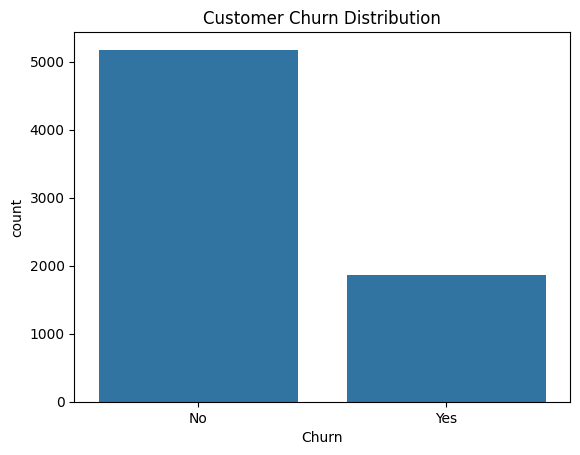

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')
plt.show()

In [14]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

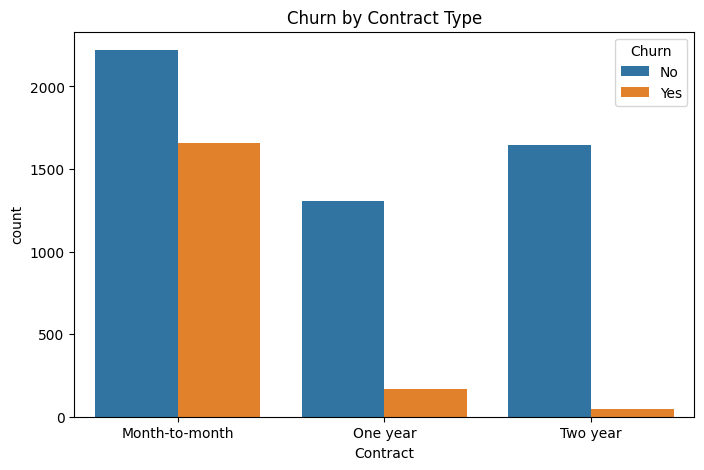

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(x='Contract', hue='Churn', data=df)

plt.title('Churn by Contract Type')
plt.show()

Customers on **month-to-month contracts** churn far more than those on one or two year contracts.

In [16]:
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


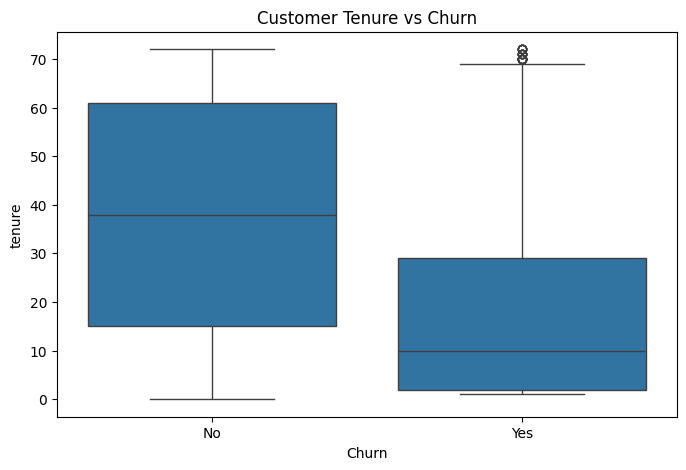

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Churn', y='tenure', data=df)

plt.title('Customer Tenure vs Churn')
plt.show()

Churned customers have a **much shorter tenure**, so new customers are the most at risk.

In [18]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

In [19]:
df['Churn'].head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [20]:
df = pd.get_dummies(df, drop_first=True)

In [21]:
df.shape

(7043, 31)

In [22]:
from sklearn.model_selection import train_test_split

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [23]:
print(X_train.shape)
print(X_test.shape)

(5634, 30)
(1409, 30)


## 5. Modeling
Two models are trained and compared:
1. **Logistic Regression** (simple, interpretable baseline)
2. **Random Forest** (non-linear ensemble model)

Since only ~27% of customers churn, accuracy alone is misleading, so I focus on **recall, F1 and ROC-AUC**.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_lr)

Accuracy: 0.8197303051809794


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    min_samples_leaf=3,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Accuracy:", accuracy_rf)

Accuracy: 0.7955997161107168


## 6. Model Evaluation & Comparison

In [26]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.89      0.83      0.86      1036
           1       0.60      0.71      0.65       373

    accuracy                           0.80      1409
   macro avg       0.74      0.77      0.75      1409
weighted avg       0.81      0.80      0.80      1409

ROC-AUC: 0.8586140238285009


In [27]:
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409

ROC-AUC: 0.8620040473257631


In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

lr_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced')
)
lr_bal.fit(X_train, y_train)

models = {'Random Forest': rf, 'Logistic Regression': lr_bal}

for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    print(f"\n{name}  (AUC = {roc_auc_score(y_test, proba):.3f})")
    for t in [0.3, 0.4, 0.5, 0.6]:
        pred = (proba >= t).astype(int)
        print(f"  threshold {t}: precision={precision_score(y_test, pred):.2f}  "
              f"recall={recall_score(y_test, pred):.2f}  f1={f1_score(y_test, pred):.2f}")


Random Forest  (AUC = 0.859)
  threshold 0.3: precision=0.47  recall=0.88  f1=0.61
  threshold 0.4: precision=0.54  recall=0.84  f1=0.66
  threshold 0.5: precision=0.60  recall=0.71  f1=0.65
  threshold 0.6: precision=0.65  recall=0.58  f1=0.61

Logistic Regression  (AUC = 0.862)
  threshold 0.3: precision=0.43  recall=0.94  f1=0.59
  threshold 0.4: precision=0.46  recall=0.88  f1=0.61
  threshold 0.5: precision=0.51  recall=0.82  f1=0.63
  threshold 0.6: precision=0.57  recall=0.74  f1=0.65


Both models reach almost the same ROC-AUC (about 0.86). **Random Forest with threshold 0.4** gives the best F1 for churners (0.66) with a high recall (0.84), so it is selected as the final model.

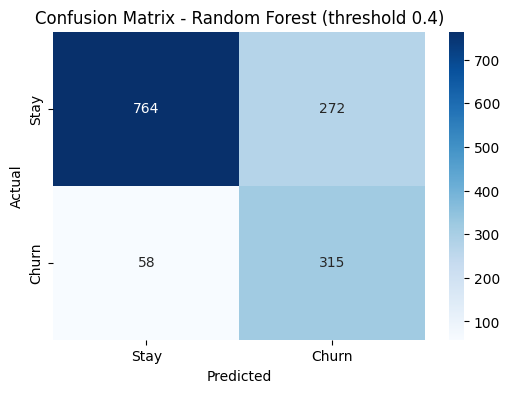

In [29]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

proba_rf = rf.predict_proba(X_test)[:, 1]
y_pred_final = (proba_rf >= 0.4).astype(int)

cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stay', 'Churn'], yticklabels=['Stay', 'Churn'])
plt.title('Confusion Matrix - Random Forest (threshold 0.4)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 7. Interpretation of Results
The final model correctly detects **315 of 373** churning customers (recall about 84%). The cost is 272 loyal customers flagged as churners (precision about 54%), which is acceptable if a retention offer is cheap compared to losing a customer.

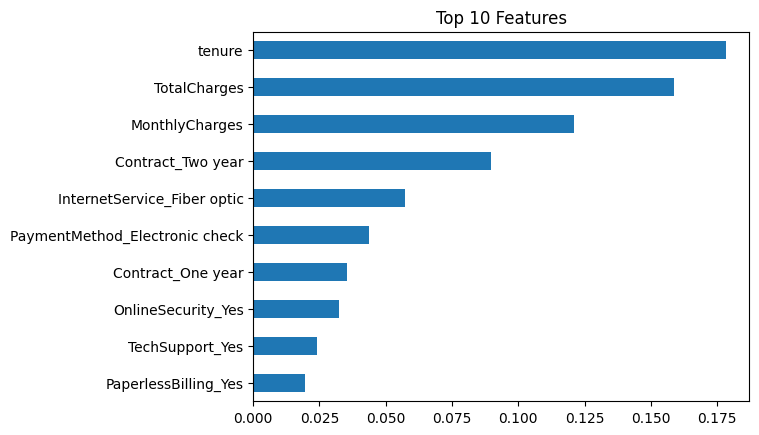

In [30]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 10 Features')
plt.show()

**Most important features:** tenure, TotalCharges, MonthlyCharges, contract type, fiber optic internet, electronic check payment, online security and tech support.

## 8. Conclusion
- Random Forest (threshold 0.4) is the final model: recall 0.84, F1 0.66, ROC-AUC 0.86.
- Logistic Regression performed almost as well and is simpler to interpret.
- Churn is driven mainly by short tenure, month-to-month contracts, high monthly charges and fiber optic service.
- **Recommendations:** offer incentives for longer contracts, target new customers with retention offers, and promote security and tech support services.
- **Limitation:** results come from a single train/test split.